### Feed Forward neural network
* A complete network from scratch
  - Feed Forward
  - Layers
  - Backpropagation
* Check gradients against jax
#### Architecture
* MSE as cost function
* Flexible number of hidden layers and nodes
  - One hidden layer using 50 nodes
  - two hidden layers using 50 and 100 nodes 
  - Sigmoid function activation for hidden layers
* Initial weights with normal distribution
* Initialize bias , how?
* Final output activation function: which one?
* How do you set up the design matrice?

#### Train and compare
* Compare the results with OLS from project 1
* Use the best data set and best polynomial degree wrt MSE




## Packages

In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp   
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.model_selection import (train_test_split,KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

## The data

(100, 1) (100, 1)


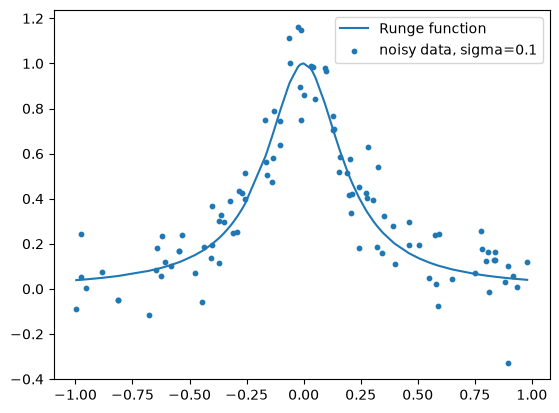

In [2]:
# The data of project 1, as a starting point for part b)
np.random.seed(2026)

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100 # 350 in Project 1
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1 # 0.25 in Project 1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
Y = y.reshape(-1, 1)  # make y a column vector for the network
print(X.shape, Y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

## Data processing
Creates a design matrice out of input values x of chosen degree and  an array out of targets y.   
Splits the data into training and test data and 
scales the data, if "Split and scale" as Process input.

In [3]:
from sklearn.model_selection import train_test_split

def Data_process(x, y,
    test_size = 0.3, Process=None):
    X = np.asarray(x).reshape(-1, 1) # make X a column vector for the network
    y = np.asarray(y).reshape(-1, 1) # make y a column vector for the network


    if Process == "Split and scale":
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=2026
        )

        # Scale polynomial features, leaving the intercept column unchanged.
        mean = X_train[:, 1:].mean(axis=0)
        std = X_train[:, 1:].std(axis=0)
        std[std == 0] = 1

        X_train[:, 1:] = (X_train[:, 1:] - mean) / std
        X_test[:, 1:] = (X_test[:, 1:] - mean) / std

        # I choose not to scale the target.
        #y_mean = y_train.mean(axis=0)
        #y_train_c = y_train - y_mean

        return X_train, X_test, y_train, y_test #y_train_c, y_test, y_mean
    
    if Process == "Scale":
        mean = X[:, 1:].mean(axis=0) 
        std = X[:, 1:].std(axis=0)
        std[std == 0] = 1
        
        X[:, 1:] = (X[:, 1:] - mean) / std

        # I choose not to scale the target.
        #y_mean = y.mean(axis=0)
        #y_c = y - y_mean
        
        return X, y  #y_c, y_mean

    if Process == None:
        return X, y

## Activation functions and MSE


In [4]:
def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))
def sigmoid_der(z):
    s = sigmoid(z)
    return s*(1 - s)
# Alternatively sigmoid_der = jax.grad(jnp.sum(sigmoid(z)))
# Identity
def identity(z):
    return z

def identity_der(z):
    return np.ones_like(z)

# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)
# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)

def mse(predict, target):
    return jnp.mean((predict - target) ** 2)
def mse_der(predict, target): # Derivative of cost function
    return 2*(predict - target)/predict.size # Mean brings a factor of 1/N, derivative brings factor 2
# Alternatively: mse_der = jax.grad(mse(predict, target))

def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

def softmax_vec(z):
    """Compute softmax values for each set of scores in the vector z.
    Use this function when you use the activation function on one vector at a time."""
    e_z = jnp.exp(z - jnp.max(z))
    return e_z / jnp.sum(e_z)

def cross_entropy(predict, target):
    # Classification cost_fun
    return -jnp.mean(
        jnp.sum(target * jnp.log(predict), axis=1)
    )

set_epoch = 10

ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_der),
               "relu": (ReLU, ReLU_der),
               "identity": (identity, identity_der),
               "softmax": (softmax, None)}


OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax} 

## Neural Network Class: Batched
### LLM Declaration: 
#### NeuralNetwork()
I am using LLM chatgpt GPT-6 Luna for learning about the usage of classes.  
The skeleton is from "Exercisesweek42.ipynb" Exercise 8 of repository MachinelearningUiO. 
I am using this skeleton, along with the solution of exerciseweek42.ipynb, to create the class. 

OpenAI assistance with translating the functions 
into working class functions.
OpenAI help with debugging the jax gradients.
OpenAI help with debugging the compute_gradients.

#### Data_processing()
--> Changed y = np.asarray(y) into y = npasarray(y).reshape(-1,1) to get y into the right shape (n,) - > (n,1) : Why this is so i do not understand, but i do understand that without this change, the code wont work in the feed forward saver as the dimensions of the last layer get off.


### Caution
Gradient methods should by handled outside, by performing
general operations on layer_grad list using functions
or classes seperate from the neural network.  
I still chose to include a short plain gradient descent
method for evolving the gradients, for testing.

In [5]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        seed,
    ):
        self.network_input_size = network_input_size
        self.layer_output_sizes = layer_output_sizes
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders 
        self.cost_fun = cost_fun
        self.cost_der = cost_der
        self.rng = np.random.default_rng(seed) # Reproducability

        # create layers = [(W , b)] with random normal weights and biases
        layers = []

        i_size = network_input_size
        for layer_output_size in layer_output_sizes:
            W = self.rng.standard_normal((i_size, layer_output_size)) / np.sqrt(i_size) # dele på sqrt(i_size)? Ja for batched
            b = np.zeros(layer_output_size) + 0.01 #np.random.randn(layer_output_size)
            layers.append((W, b))

            i_size = layer_output_size
        
        self.layers = layers

    def predict(self, inputs):
        # Simple feed forward pass
        a = jnp.asarray(inputs) 
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def cost(self, inputs, targets):
        predictions = self.predict(inputs)
        #print("Prediksjoner:", predictions.shape)
        #print("Fasit:", targets.shape)
        #print("Kostfunksjon:", self.cost_fun.__name__)

        mse = self.cost_fun(predictions,targets)
        return mse

    def _feed_forward_saver(self, inputs):
        layer_inputs = []
        zs = []
        a = jnp.asarray(inputs)
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            #print("a",a.shape)
            #print("W",W.shape)
            #print("b", b.shape)
            z = a @ W + b
            zs.append(z)
            a = activation_func(z)
        return layer_inputs, zs, a 

    def compute_gradient_standard(self, inputs, targets):
        # Backpropagation
        # dC_dW = dC_da @ da_dz @ dz_dW
        # dC_db = dC_da @ da_dz @ dz_db
        layer_inputs, sz, predict = self._feed_forward_saver(
            inputs)
        layer_grads = [() for layer in self.layers]

        for l in reversed(range(len(self.layers))):
            layer_input, z, activation_der = layer_inputs[l], sz[l], self.activation_ders[l]

            if l == (len(self.layers) - 1): # last layer
                dC_da = self.cost_der(predict, targets)
            else:
                (W, b) = self.layers[l + 1]
                #print("layer", l)
                #print("predictions:", predict.shape)
                #print("targets:", targets.shape)
                #print("dC_dz:", dC_dz.shape)
                #print("W:", W.shape)
                dC_da = dC_dz @ (W.T) 

            dC_dz = dC_da * activation_der(z) # Hadamard
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis=0) # what happened here?

            layer_grads[l] = (dC_dW, dC_db)
            #print("layer", l)
            #print("predictions:", predict.shape)
            #print("targets:", targets.shape)
            #print("dC_dz:", dC_dz.shape)
        return layer_grads

    def compute_gradient_softmax(self, inputs, targets):
        "Exercicesweek42.ipynb"
        layer_inputs, sz, predict = self._feed_forward_saver(inputs)
        layer_grads = [None] * len(self.layers) # AI assisted for simplicity GPT LUNA 6.1
        n = inputs.shape[0]

        for l in reversed(range(len(self.layers))):
            layer_input = layer_inputs[l]

            if l == len(self.layers) - 1:
                # Softmax + mean cross entropy
                dC_dz  = (predict - targets)/n
            else:
                (W, b) = self.layers[l + 1] # W_next, b_next
                z = sz[l]
                activation_der = self.activation_ders[l]
                dC_dz = (dC_dz @ W.T) * activation_der(z)
        
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis = 0)

            layer_grads[l] = (dC_dW, dC_db)

        return layer_grads

    def compute_gradient(self, inputs, targets):
        "AI Declaration: Created with help of GPT-6.1 Sol for SGD function compute_gradient"
        if self.activation_funcs[-1] is softmax:
            return self.compute_gradient_softmax(inputs, targets)

        return self.compute_gradient_standard(inputs, targets)

    
    def accuracy(self, predictions, targets):
        "Exerciseweek42: Classification"
        one_hot_predictions = np.zeros(predictions.shape)

        for i, prediction in enumerate(predictions):
            one_hot_predictions[i, np.argmax(prediction)] = 1
        return accuracy_score(one_hot_predictions, targets) # ski-kit function

    # These last two methods are not needed in the project, but they can be nice to have!
    # This should be External! But i can try use plain gradient
    # BEWARE: Using this function will change the local variable self.layers in the object
    def update_weights_plain(self, layer_grads, gamma=0.05):
        self.layers = [
        (W - gamma * W_g, b - gamma * b_g)
        for (W, b), (W_g, b_g) in zip(self.layers, layer_grads)]


    # jax solution
    # The first one has a layers parameter so that you can use jax.grad on it.
    
    def jax_compliant_predict(self, layers, inputs):
        a = jnp.asarray(inputs)

        for (W, b), activation_func in zip(layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def jax_cost(self, layers, inputs, targets):
        predictions = self.jax_compliant_predict(layers, inputs)
        mse = self.cost_fun(predictions, targets)
        return mse

    def jax_gradient(self, inputs, targets):
        grads = jax.grad(self.jax_cost,argnums = 0)(self.layers, inputs, targets)
        return grads

## Class Optimizer

In [6]:
class Optimizer:
    """Oppdaterer nettverkslag med plain gradient descent, Adam eller RMSprop."""

    def __init__(
        self, method, gamma,
        beta1=0.9, beta2=0.999, rho=0.99, eps=1e-8
    ):
        self.method = method.lower()
        self.gamma = gamma
        self.beta1 = beta1
        self.beta2 = beta2
        self.rho = rho
        self.eps = eps

        self.state = None
        self.t = 0

    def zero_state(self, layers):
        """Lag nullstilte momentverdier for Adam og RMSprop."""
        return [
            (
                np.zeros_like(W),  # mW
                np.zeros_like(b),  # mb
                np.zeros_like(W),  # vW
                np.zeros_like(b),  # vb
            )
            for W, b in layers
        ]

    def initialize(self, layers):
        """Start en ny treningskjøring."""
        self.t = 0

        if self.method == "plain":
            self.state = None
        else:
            self.state = self.zero_state(layers)

    def step(self, layers, layer_grads, gamma=None):
        """Utfør én minibatchoppdatering."""
        if gamma is None:
            gamma = self.gamma

        self.t += 1

        if self.method == "plain":
            return self.step_plain(layers, layer_grads, gamma)

        if self.state is None:
            raise RuntimeError("Kjør optimizer.initialize(layers) før trening.")

        if self.method == "adam":
            return self.step_adam(layers, layer_grads, gamma)

        if self.method == "rmsprop":
            return self.step_rmsprop(layers, layer_grads, gamma)

        raise ValueError("method må være 'plain', 'adam' eller 'rmsprop'")

    def step_plain(self, layers, layer_grads, gamma):
        return [
            (W - gamma * dW, b - gamma * db)
            for (W, b), (dW, db) in zip(layers, layer_grads)
        ]

    def step_rmsprop(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            vW = self.rho * vW + (1 - self.rho) * dW**2
            vb = self.rho * vb + (1 - self.rho) * db**2

            W = W - gamma * dW / (np.sqrt(vW) + self.eps)
            b = b - gamma * db / (np.sqrt(vb) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

    def step_adam(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            mW = self.beta1 * mW + (1 - self.beta1) * dW
            mb = self.beta1 * mb + (1 - self.beta1) * db
            vW = self.beta2 * vW + (1 - self.beta2) * dW**2
            vb = self.beta2 * vb + (1 - self.beta2) * db**2

            mW_hat = mW / (1 - self.beta1**self.t)
            mb_hat = mb / (1 - self.beta1**self.t)
            vW_hat = vW / (1 - self.beta2**self.t)
            vb_hat = vb / (1 - self.beta2**self.t)

            W = W - gamma * mW_hat / (np.sqrt(vW_hat) + self.eps)
            b = b - gamma * mb_hat / (np.sqrt(vb_hat) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

## Func SGD Train

In [7]:
def step_length(t, t0, t1):
    """A decaying learning-rate schedule."""
    return t0 / (t + t1)

def train_sgd(
    network, X, y, method="adam",
    epochs=set_epoch, batch_size=5, gamma=0.001, lmb = 0.0, penalty ="l2", schedule=None, seed=2026
):
    "LLM Assisted: Using the class netowrk"
    rng = np.random.default_rng(seed)

    X = np.asarray(X)
    y = np.asarray(y) #.reshape(-1, 1)

    # Bruk av klasse
    optimizer = Optimizer(method=method, gamma=gamma)
    optimizer.initialize(network.layers)

    # Tilstanden er en liste med tupler, ett for hvert lag.
    state = None if method == "plain" else optimizer.zero_state(network.layers)
    t = 0
    history = []
    history_test = []
    
    for epoch in range(epochs):
        # Bland rekkefølgen på datapunktene for hver epoke.
        indices = rng.permutation(len(X))
        # Minibatch
        for start in range(0, len(X), batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X[batch]
            y_batch = y[batch]

            # Hent gradientene fra nettverksobjektet.
            layer_grads = network.compute_gradient(X_batch, y_batch)

            #L2 norm - Ridge
            "AI Declaration: Help from codex GPT-LUNA6.1 for task 2b) L1 and L2 placement"
            if penalty == "l2":
                layer_grads = [
                (dW + 2 * lmb * W, db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)]
            #L1 norm - Lasso
            #"AI Declaration: Help from codex GPT-Luna6.1"
            elif penalty == "l1":
                layer_grads = [
                (dW + lmb * np.sign(W), db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)
                ]
            elif penalty is not None:
                raise ValueError("penalty må være 'l1', 'l2' eller None")

            # Tell minibatchoppdateringer. Adam bruker t til korreksjon
            # for oppstartsfasen.
            t += 1
            gamma = gamma if schedule is None else step_length(t - 1, *schedule)
            network.layers = optimizer.step(network.layers, layer_grads)

        # Kostnaden etter at hele treningssettet har vært gjennom én gang.
        epoch_cost = float(network.cost(X, y))
        history.append(epoch_cost)
    

    return history, network.layers

## Func PGD train

In [8]:
def train_plain(
    network, X, y, gamma=0.001, lmb = 0.0, penalty = None, epochs=set_epoch, seed = 2026
    ):
    rng = np.random.default_rng(seed)
    inputs = np.asarray(X)
    targets = np.asarray(y)
    
    optimizer = Optimizer(method="plain", gamma=gamma)
    optimizer.initialize(network.layers)
    state = None
    history = []
    

    for i in range(epochs):
        layer_grads = network.compute_gradient(inputs, targets)
        
        "Cope from SGD_train()"
        if penalty == "l2":
            layer_grads = [
            (dW + 2 * lmb * W, db)
            for (W, b), (dW, db) in zip(network.layers, layer_grads)]
        elif penalty == "l1":
            layer_grads = [
            (dW + lmb * np.sign(W), db)
            for (W, b), (dW, db) in zip(network.layers, layer_grads)
            ]
        elif penalty is not None:
            raise ValueError("penalty må være 'l1', 'l2' eller None")
        
        network.layers = optimizer.step(network.layers, layer_grads)
        
        cost = float(network.cost(inputs, targets))
        history.append((cost))
            

    return history, network.layers

## NeuralNetClassifier
The same wrapper with `ClassifierMixin` instead of `RegressorMixin`:
`fit(X, y)` takes integer labels (one-hot encode them inside `fit`, and set
`self.classes_ = np.unique(y)`), `predict(X)` returns the integer labels
(`np.argmax` of the softmax output) and `predict_proba(X)` the class
probabilities. Use a **stratified subset of 10 000 training images** (1000
per digit) for everything but the last step, `StratifiedKFold(5,
shuffle=True, random_state=2026)` so that every fold has every digit in the
right proportion, and the metric functions of week 43.

In [17]:
class NeuralNetClassifier(BaseEstimator, ClassifierMixin):
    "AI Declaration"
    def __init__(self, 
    hidden=(64,), activation="relu", 
    gamma=0.1, lmbd=0.0, 
    penalty=None, method = "plain",
    epochs=20, batch_size=100, 
    seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.penalty = penalty 
        self.method = method
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        """LLM Assistance: Creating the activation funcs in correct format"""
        hidden_func, hidden_der = ACTIVATIONS[self.activation]
        activation_funcs = [hidden_func] * len(self.hidden) + [softmax]
        activation_ders = [hidden_der] * len(self.hidden) + [None]

        self.classes_, class_indices = np.unique(y, return_inverse=True) # AI assisted
        n_classes = len(self.classes_) #AI assisted

        # Én rad per datapunkt, én kolonne per klasse.
        # AI assisted: Onehot encoding, Right form for cross entropy 
        targets = np.eye(n_classes)[class_indices] 
        
        self.network = NeuralNetwork(
            network_input_size=X.shape[1],
            layer_output_sizes = (*self.hidden, n_classes), # AI Assistance: Correction of sizes for one-hot
            activation_funcs = activation_funcs, 
            activation_ders = activation_ders,
            cost_fun = cross_entropy,
            cost_der = None,
            seed=self.seed
        )
        
        self.history, self.layer = train_sgd(self.network,
        X, targets, method = self.method, epochs = self.epochs,
        batch_size = self.batch_size, gamma = self.gamma, lmb = self.lmbd, 
        penalty = self.penalty, seed = self.seed)


        return self

    def predict_proba(self, X):
        # AI Declaration: GPT-61 Sol help
        return np.asarray(self.network.predict(X))

    def predict(self, X):
        # AI Declaration: GPT-61 Sol help
        probabilities = self.predict_proba(X)
        class_indices = np.argmax(probabilities, axis=1)
        return self.classes_[class_indices]

    def accuracy(self, predictions, targets):
        return accuracy_score(predictions, targets) # ski-kit function

## Mnist data

In [ ]:
data = np.load("mnist.npz")               # see Project 2 for where to get it
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
y_train = data["y_train"]
rng = np.random.default_rng(2026)
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
X_sub, y_sub = x_train[sub], y_train[sub]


# Don`t touch this!
x_test_full = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_test_full = data["y_test"]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

## Stratified KFold

In [21]:
acc_fold = []
for fold, (train_index, test_index) in enumerate(
    cv_strat.split(X_sub, y_sub), start=1):
    X_train, X_test = X_sub[train_index], X_sub[test_index]
    y_train, y_test = y_sub[train_index], y_sub[test_index]

    NN_class = NeuralNetClassifier(method="plain")
    NN_class.fit(X_train, y_train)
    predictions = NN_class.predict(X_test)
    acc = NN_class.accuracy(predictions, y_test)
    acc_fold.append(acc)
    #print(f"Fold {fold}")
    #print("TRAIN:", train_index)
    #print("TEST:", test_index)

print("Accuracy per fold:", acc_fold)
print(f"Gjennomsnitt: {np.mean(acc_fold):.2%}")
print(f"Standardavvik: {np.std(acc_fold):.2%}")

Accuracy per fold: [0.926, 0.938, 0.926, 0.9165, 0.932]
Gjennomsnitt: 92.77%
Standardavvik: 0.72%


## Logistic Regression

In [22]:
acc_fold_L = []
for fold, (train_index, test_index) in enumerate(
    cv_strat.split(X_sub, y_sub), start=1):
    X_train, X_test = X_sub[train_index], X_sub[test_index]
    y_train, y_test = y_sub[train_index], y_sub[test_index]

    model = LogisticRegression(
    solver="saga", max_iter=1000, random_state=2026
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    acc_fold_L.append(accuracy)
print("Accuracy per fold:", acc_fold_L)
print(f"Gjennomsnitt: {np.mean(acc_fold_L):.2%}")
print(f"Standardavvik: {np.std(acc_fold_L):.2%}")


Accuracy per fold: [0.8955, 0.901, 0.902, 0.8925, 0.904]
Gjennomsnitt: 89.90%
Standardavvik: 0.43%


## Gridsearch

In [ ]:
# Gridsearch
net_class = make_pipeline(StandardScaler(), NeuralNetClassifier())
param_grid = {"neuralnetclassifier__hidden": [(32,), (64,), (128,)],
              "neuralnetclassifier__gamma": [0.0001, 0.001, 0.01, 0.03, 0.1],
              "neuralnetclassifier__method": ["plain", "adam", "rmsprop"],
              "neuralnetclassifier__penalty": [None, "l1", "l2"]}
              

# Can include "neuralnetclassifier__activation": ["relu", "sigmoid"]
search_class = GridSearchCV(net_class, param_grid, cv=cv_strat, scoring="accuracy",return_train_score=True,n_jobs=-1)
search_class.fit(X_sub, y_sub)

/Users/timholmen/FYS-STK4155/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
810 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
810 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/timholmen/FYS-STK4155/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/timholmen/FYS-STK4155/.venv/lib/python3.13/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/Users/timholmen/FYS-STK4155/.venv/lib/pytho

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'neuralnetclassifier__activation': ['sigmoid', 'relu', ...], 'neuralnetclassifier__gamma': [0.01, 0.03, ...], 'neuralnetclassifier__hidden': [(32,), (64,), ...], 'neuralnetclassifier__method': ['plain', 'adam', ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for m

In [29]:
# LLM Assisted: Finding best values within search_class.cv_results_
# Classification results: accuracy is maximized, unlike regression MSE.
class_results = search_class.cv_results_
class_cv_accuracy = np.asarray(class_results["mean_test_score"])
# std_test_score uses ddof=0; this gives the estimated SE across folds.
class_cv_se = np.asarray(class_results["std_test_score"]) / np.sqrt(search_class.n_splits_ - 1)
class_best_index = search_class.best_index_
class_best_params = class_results["params"][class_best_index]
class_best_accuracy = class_cv_accuracy[class_best_index]
class_best_se = class_cv_se[class_best_index]
class_one_se_limit = class_best_accuracy - class_best_se

print("CV accuracy per candidate:", class_cv_accuracy)
print("SE per candidate:", class_cv_se)
print(search_class.best_estimator_)
print(class_best_params)
print(f"Best CV accuracy: {class_best_accuracy:.2%} +/- SE: {class_best_se:.2%}")
print(f"One-SE lower limit: {class_one_se_limit:.2%}")

# Look for smaller networks whose accuracy is within one SE of the best.
# Look for smaller networks within one SE of the best.
class_smaller_found = False

for class_index, class_params in enumerate(class_results["params"]):
    class_gamma = class_params["neuralnetclassifier__gamma"]
    class_hidden = class_params["neuralnetclassifier__hidden"]
    class_method = class_params["neuralnetclassifier__method"]
    class_penalty = class_params["neuralnetclassifier__penalty"]

    if (
        class_cv_accuracy[class_index] >= class_one_se_limit
        and sum(class_hidden)
        < sum(class_best_params["neuralnetclassifier__hidden"])
    ):
        class_smaller_found = True

        print(
            f"gamma={class_gamma:g}, "
            f"hidden={class_hidden}, "
            f"method={class_method}, "
            f"penalty={class_penalty}: "
            f"CV accuracy={class_cv_accuracy[class_index]:.2%} "
            f"+/- SE={class_cv_se[class_index]:.2%}"
        )

if not class_smaller_found:
    print("No smaller network has CV accuracy within one SE of the best.")

CV accuracy per candidate: [0.8562    nan    nan 0.9149    nan    nan 0.9088    nan    nan 0.8633
    nan    nan 0.9288    nan    nan 0.9251    nan    nan 0.8654    nan
    nan 0.9366    nan    nan 0.9321    nan    nan 0.8945    nan    nan
 0.9075    nan    nan 0.9037    nan    nan 0.8958    nan    nan 0.9094
    nan    nan 0.9131    nan    nan 0.8948    nan    nan 0.9125    nan
    nan 0.9173    nan    nan 0.9136    nan    nan 0.8715    nan    nan
 0.8728    nan    nan 0.9159    nan    nan 0.8759    nan    nan 0.8714
    nan    nan 0.9154    nan    nan 0.8881    nan    nan 0.8701    nan
    nan 0.9077    nan    nan 0.9291    nan    nan 0.9274    nan    nan
 0.9088    nan    nan 0.9333    nan    nan 0.929     nan    nan 0.9153
    nan    nan 0.9319    nan    nan 0.933     nan    nan 0.9229    nan
    nan 0.9193    nan    nan 0.9182    nan    nan 0.9267    nan    nan
 0.9273    nan    nan 0.9281    nan    nan 0.9326    nan    nan 0.9301
    nan    nan 0.9288    nan    nan 0.9292    nan 

ValueError: Index contains duplicate entries, cannot reshape

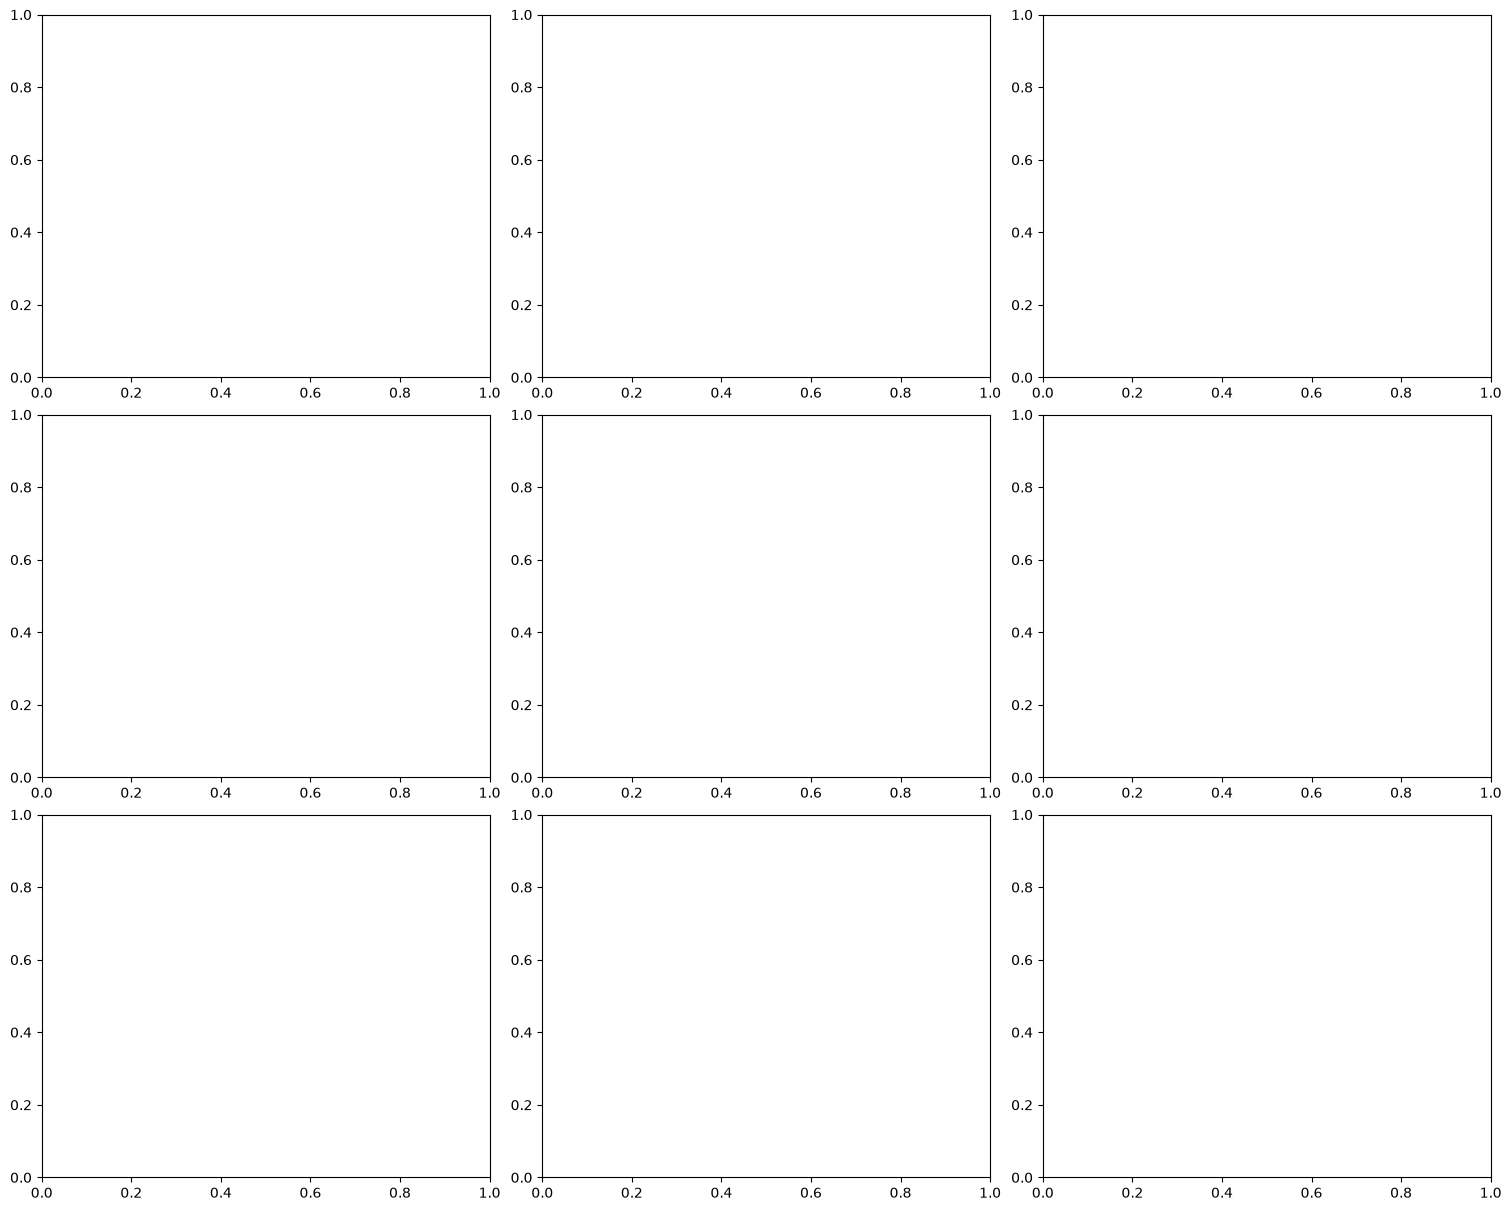

In [32]:
from matplotlib.ticker import PercentFormatter
import pandas as pd

results = search_class.cv_results_

df = pd.DataFrame([
    {
        "method": p["neuralnetclassifier__method"],
        "penalty": str(p["neuralnetclassifier__penalty"]),
        "hidden": str(p["neuralnetclassifier__hidden"]),
        "gamma": p["neuralnetclassifier__gamma"],
        "accuracy": score,
    }
    for p, score in zip(
        results["params"], results["mean_test_score"]
    )
])

methods = df["method"].unique()
penalties = df["penalty"].unique()
gammas = sorted(df["gamma"].unique())
hidden_sizes = [
    str(h) for h in sorted(
        {p["neuralnetclassifier__hidden"] for p in results["params"]},
        key=lambda h: (sum(h), h),
    )
]

# Global one-SE limit across all configurations.
best_index = search_class.best_index_
best_accuracy = results["mean_test_score"][best_index]
best_se = (
    results["std_test_score"][best_index]
    / np.sqrt(search_class.n_splits_ - 1)
)
one_se_limit = best_accuracy - best_se

vmin = df["accuracy"].min()
vmax = df["accuracy"].max()

fig, axes = plt.subplots(
    len(penalties), len(methods),
    figsize=(5 * len(methods), 4 * len(penalties)),
    squeeze=False,
    constrained_layout=True,
)

for row, penalty in enumerate(penalties):
    for col, method in enumerate(methods):
        ax = axes[row, col]

        subset = df[
            (df["method"] == method)
            & (df["penalty"] == penalty)
        ]

        grid = subset.pivot(
            index="gamma", columns="hidden", values="accuracy"
        ).reindex(index=gammas, columns=hidden_sizes)

        im = ax.imshow(
            grid.values,
            origin="lower",
            aspect="auto",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
        )

        ax.set_xticks(range(len(hidden_sizes)), hidden_sizes)
        ax.set_yticks(range(len(gammas)), gammas)
        ax.set_xlabel("Hidden layers")
        ax.set_ylabel("Learning rate γ")
        ax.set_title(f"{method}, penalty={penalty}")

        for (r, c), accuracy in np.ndenumerate(grid.values):
            if not np.isfinite(accuracy):
                continue

            ax.text(
                c, r, f"{accuracy:.2%}",
                ha="center",
                va="center",
                color="white" if accuracy < (vmin + vmax) / 2 else "black",
            )

            if accuracy >= one_se_limit:
                ax.add_patch(plt.Rectangle(
                    (c - 0.45, r - 0.45), 0.9, 0.9,
                    fill=False,
                    edgecolor="white",
                    linestyle="--",
                    linewidth=2,
                ))

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="CV accuracy",
    format=PercentFormatter(xmax=1),
)

fig.suptitle(
    f"Classification — dashed boxes: accuracy ≥ {one_se_limit:.2%}"
)

plt.show()